# Atividade Prática 4: Manipulaçãao e Decisões de Visualização de Dados das IFES (1996–2026)
**Alunos:** Arthur Vieira Silva e Matheus Barbosa Brandão  

In [117]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.interpolate import make_interp_spline

# Configurações estéticas globais
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

## 1. Carregar, Preparar e Explorar os Dados:

In [118]:
# Carregando dataset:
df = pd.read_csv('dados_investimento_e_vagas_ifes.csv')

df.head()

df.describe()

,ano,investimento_total_ifes_bilhoes_brl,investimento_assistencia_estudantil_bilhoes_brl,num_vagas_estudantes,num_vagas_docente,num_vagas_tae,num_terceirizados
count,31.000000,31.000000,31.000000,3.100000e+01,31.000000,31.000000,31.000000
mean,2011.000000,53.019355,0.693548,8.967581e+05,64316.129032,61212.903226,34812.903226
std,9.092121,15.830802,0.534749,4.008678e+05,28928.787240,14261.410448,18120.425711
min,1996.000000,29.800000,0.020000,3.421000e+05,26800.000000,41500.000000,8200.000000
25%,2003.500000,34.350000,0.070000,4.659500e+05,30650.000000,43800.000000,14300.000000
50%,2011.000000,54.100000,0.920000,9.845000e+05,73100.000000,69800.000000,41200.000000
75%,2018.500000,65.950000,1.210000,1.305000e+06,92850.000000,73150.000000,48850.000000
max,2026.000000,76.500000,1.320000,1.385000e+06,98100.000000,77400.000000,59100.000000


In [119]:
## 2. Evolução Temporal e Ajuste de Escalas (Tomada de Decisão):

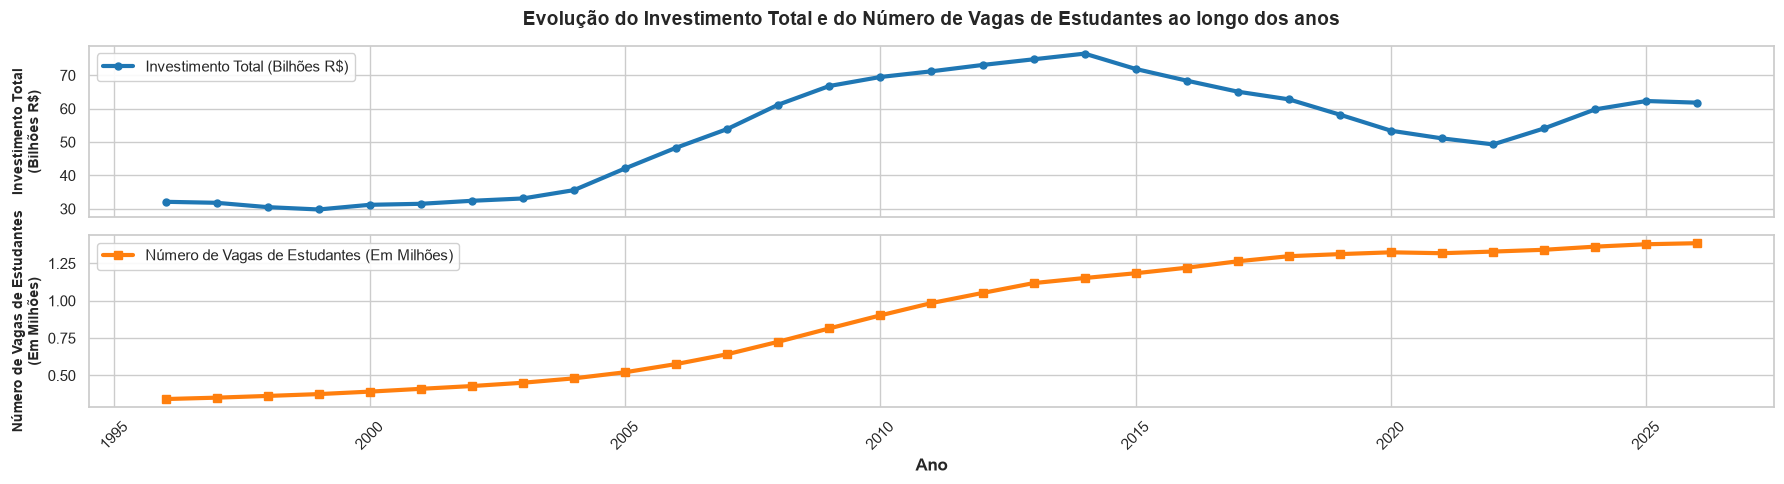

In [120]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 5), sharex=True)

# Agrupando por ano:
groups = df.groupby('ano')[['investimento_total_ifes_bilhoes_brl', 'num_vagas_estudantes']].sum().reset_index()

# Gráfico Superior - Investimento Total:
ax1.plot(groups['ano'], groups['investimento_total_ifes_bilhoes_brl'], marker='o', markersize=5, linewidth=3, label='Investimento Total (Bilhões R$)', color='#1f77b4')
ax1.set_ylabel('Investimento Total\n(Bilhões R$)', fontsize=10, fontweight='bold')
ax1.yaxis.set_major_locator(MultipleLocator(10))
ax1.tick_params(axis='x', rotation=45)

ax1.set_title('Evolução do Investimento Total e do Número de Vagas de Estudantes ao longo dos anos', fontsize=14, fontweight='bold', pad=15)

ax1.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

# Gráfico Inferior - Número de Vagas de Estudantes:
ax2.plot(groups['ano'], groups['num_vagas_estudantes'] / 1e6, marker='s', linewidth=3, label='Número de Vagas de Estudantes (Em Milhões)', color='#ff7f0e')
ax2.set_xlabel('Ano', fontsize=12, fontweight='bold')
ax2.set_ylabel('Número de Vagas de Estudantes\n(Em Milhões)', fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)

ax2.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

fig.align_ylabels([ax1, ax2])

plt.tight_layout()

plt.show()

## 3. Análise de Proporção de Força de Trabalho (Docentes vs. TAEs):

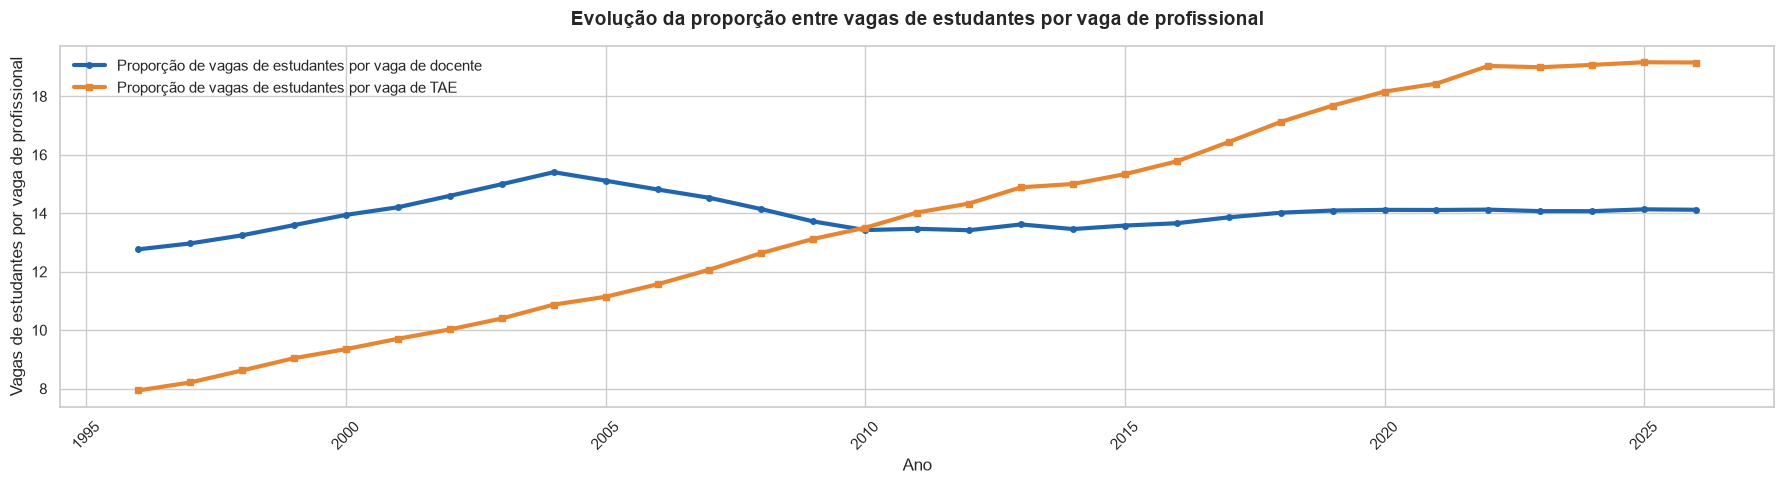

In [121]:
df_modified = df.copy()

# Proporção de vagas de estudantes por vaga de docente:
df_modified['proporcao_estudante_docente'] = (
    df['num_vagas_estudantes'] / df['num_vagas_docente']
    )

# Proporção de vagas de estudantes por vaga de Técnico-Administrativo em Educação (TAE):
df_modified['proporcao_estudante_tae'] = (
    df['num_vagas_estudantes'] / df['num_vagas_tae']
    )

df_modified[['ano', 'proporcao_estudante_docente', 'proporcao_estudante_tae']].head()

fig, ax = plt.subplots(figsize=(18, 5))

ax.plot(df_modified['ano'], df_modified['proporcao_estudante_docente'], marker='o', markersize=4, linewidth=3, label='Proporção de vagas de estudantes por vaga de docente', color='#2166AC')
ax.plot(df_modified['ano'], df_modified['proporcao_estudante_tae'], marker='s', markersize=4, linewidth=3, label='Proporção de vagas de estudantes por vaga de TAE', color='#E68632')

ax.set_title('Evolução da proporção entre vagas de estudantes por vaga de profissional', fontsize=14, fontweight='bold', pad=15)

ax.set_xlabel('Ano')
ax.set_ylabel('Vagas de estudantes por vaga de profissional')

ax.tick_params(axis='x', rotation=45)
ax.legend(loc='best', frameon=False)

plt.tight_layout()

plt.show()

## 4. Correlação entre Fatores e Desempenho Orçamentário (Método agg):

investimento_assistencia_estudantil_bilhoes_brl                \
                                                     mean median    sum   
periodos                                                                  
1996-2005                                        0.049000   0.04   0.49   
2006-2015                                        0.809000   0.85   8.09   
2016-2026                                        1.174545   1.21  12.92   

          num_vagas_estudantes                       
                          mean     median       sum  
periodos                                             
1996-2005         4.116300e+05   401150.0   4116300  
2006-2015         9.151200e+05   943300.0   9151200  
2016-2026         1.321091e+06  1324000.0  14532000

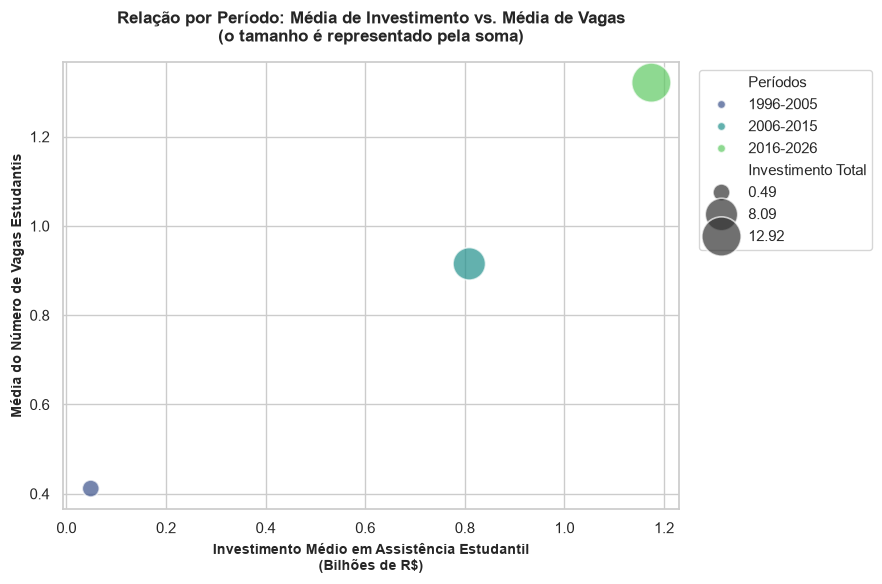

In [122]:
df_modified = df.copy()

# Dividindo os anos em três períodos:
df_modified['periodos'] = pd.cut(
    df['ano'], 
    bins=[1995, 2005, 2015, 2026], 
    labels=['1996-2005', '2006-2015', '2016-2026']
    )

groups = df_modified.groupby('periodos', observed=True).agg({
    'investimento_assistencia_estudantil_bilhoes_brl': [
        'mean',
        'median',
        'sum'
    ],
    'num_vagas_estudantes': [
        'mean',
        'median',
        'sum'
    ]
})

display(groups)

# Renomeando as colunas:
groups.columns = ['investimento_media', 'investimento_mediana', 'investimento_total',
                  'vagas_media', 'vagas_mediana', 'vagas_total']
groups = groups.reset_index()

groups['vagas_media_milhoes'] = groups['vagas_media'] / 1e6 # convertendo as vagas para milhões

# Gráfico de Bolhas (Scatter Plot com 'size')
plt.figure(figsize=(9, 6))

ax = sns.scatterplot(
    data=groups,
    x='investimento_media',
    y='vagas_media_milhoes',
    size='investimento_total',
    hue='periodos',
    sizes=(150, 800),
    alpha=0.7,
    palette='viridis'
)

handles, labels = ax.get_legend_handles_labels()

for i, label in enumerate(labels):
    if label == 'periodos':
        labels[i] = 'Períodos'
    elif label == 'investimento_total':
        labels[i] = 'Investimento Total'

plt.title('Relação por Período: Média de Investimento vs. Média de Vagas\n(o tamanho é representado pela soma)', fontsize=12, fontweight='bold', pad=15)

plt.xlabel('Investimento Médio em Assistência Estudantil\n(Bilhões de R$)', fontsize=10, fontweight='bold')
plt.ylabel('Média do Número de Vagas Estudantis', fontsize=10, fontweight='bold')
ax.legend(handles=handles, labels=labels, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()

plt.show()

## 5. Filtragem Condicional de Anos Críticos (filter):

Anos críticos:


,ano,investimento_assistencia_estudantil_bilhoes_brl,num_vagas_estudantes
1,1997,0.02,351400
3,1999,0.03,375200
5,2001,0.04,410500
19,2015,1.28,1184000
21,2017,1.25,1264000
22,2018,1.22,1298000
23,2019,1.18,1312000
24,2020,1.15,1324000
26,2022,0.98,1329000
30,2026,1.22,1385000


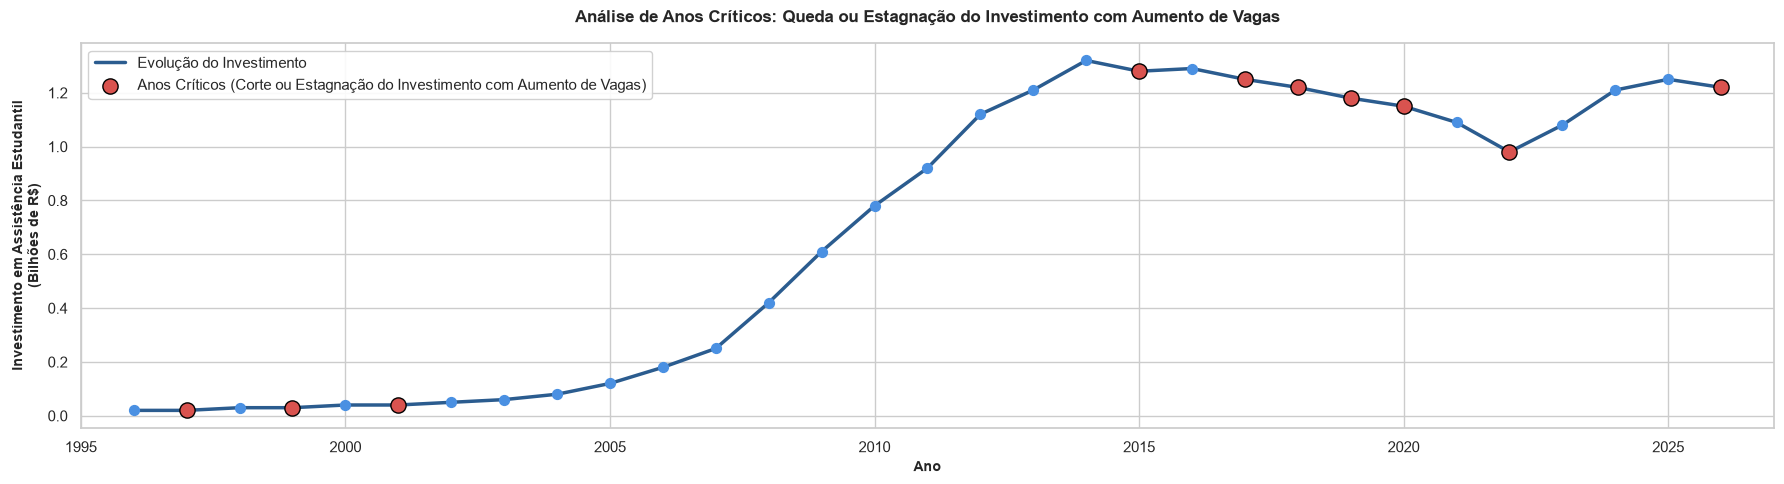

In [123]:
df_modified = df.copy()

# Criando as colunas para verificar a diferença em relação ao ano anterior:
df_modified['variacao_investimento_assistencia_estudantil'] = df_modified['investimento_assistencia_estudantil_bilhoes_brl'].diff()
df_modified['variacao_num_vagas_estudantes'] = df_modified['num_vagas_estudantes'].diff()

# Filtrando os anos críticos (em que houve corte ou estagnação no investimento em assistência estudantil, 
# mesmo com o aumento no número total de vagas para estudantes)
anos_criticos = df_modified[
    (df_modified['variacao_investimento_assistencia_estudantil'] <= 0) & 
    (df_modified['variacao_num_vagas_estudantes'] > 0)
]

print("Anos críticos:")
display(anos_criticos[['ano', 'investimento_assistencia_estudantil_bilhoes_brl', 'num_vagas_estudantes']])

plt.figure(figsize=(18, 5))

# Série Temporal principal:
plt.plot(
    df_modified['ano'], 
    df_modified['investimento_assistencia_estudantil_bilhoes_brl'], 
    color='#2b5c8f', 
    linewidth=2.5, 
    label='Evolução do Investimento'
)

# Anos não críticos (marcadores azuis):
plt.scatter(
    df_modified['ano'], 
    df_modified['investimento_assistencia_estudantil_bilhoes_brl'], 
    color='#4a90e2', 
    s=50, 
    zorder=3
)

# Anos críticos (marcadores vermelhos e maiores):
plt.scatter(
    anos_criticos['ano'], 
    anos_criticos['investimento_assistencia_estudantil_bilhoes_brl'], 
    color='#d9534f', 
    s=120,       
    zorder=4,
    edgecolors='black',
    label='Anos Críticos (Corte ou Estagnação do Investimento com Aumento de Vagas)'
)

plt.title('Análise de Anos Críticos: Queda ou Estagnação do Investimento com Aumento de Vagas', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ano', fontsize=10, fontweight='bold')
plt.ylabel('Investimento em Assistência Estudantil\n(Bilhões de R$)', fontsize=10, fontweight='bold')

plt.xlim(1995, 2027)

plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

## 6. Métricas Customizadas via apply e Paletas de Cores:

Contagem de Anos por Categoria Institucional:


categoria_consolidacao_institucional
Retração Orçamentária    12
Média Expansão           11
Alta Expansão             8
Name: count, dtype: int64

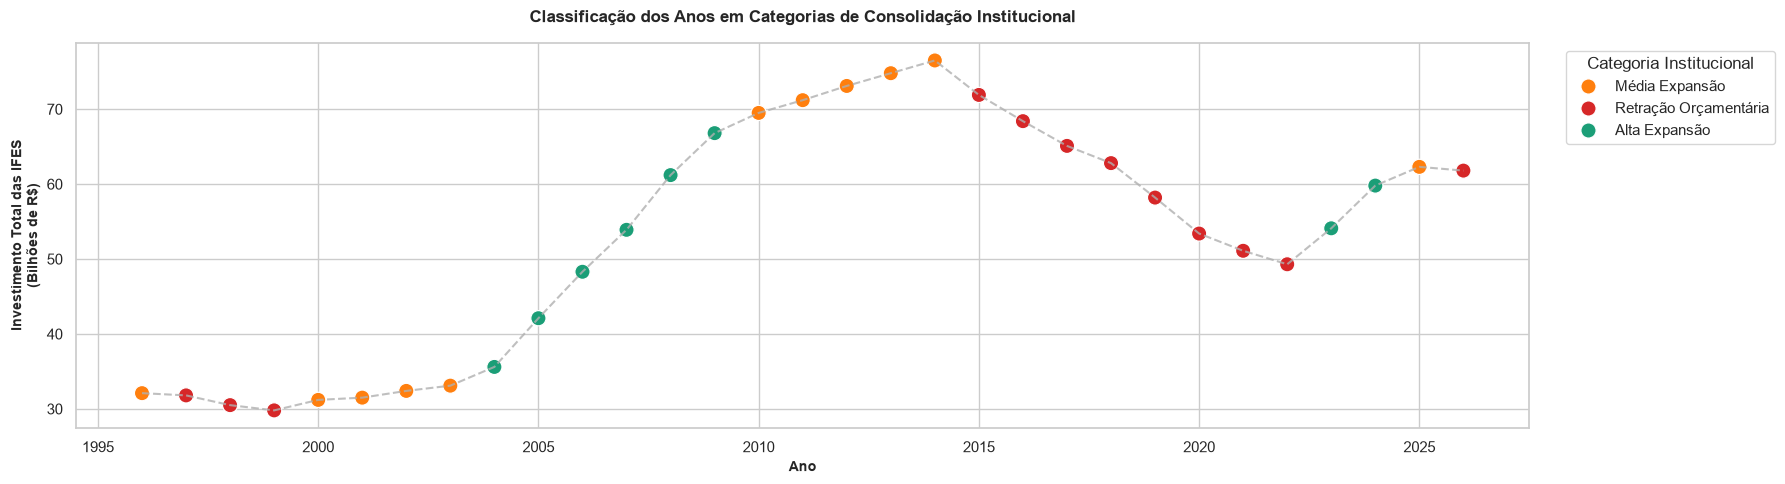

In [125]:
df_modified = df.copy()

# Calculando a variação percentual ou absoluta do investimento total:
df_modified['variacao_investimento_total'] = df_modified['investimento_total_ifes_bilhoes_brl'].pct_change() * 100

def classify_institutional_consolidation(row):
    """
        Função utilizada para classificar cada ano em categorias de consolidação institucional (ex. "Alta Expansão",
        "Média Expansão", "Retração Orçamentária").
    """

    # Verifica se é o primeiro ano ou se não há dado anterior:
    if pd.isna(row['variacao_investimento_total']):
        return 'Média Expansão'
    
    if row['variacao_investimento_total'] > 5.0:
        return 'Alta Expansão'
    
    elif row['variacao_investimento_total'] >= 0:
        return 'Média Expansão'
    
    else:
        return 'Retração Orçamentária'

df_modified['categoria_consolidacao_institucional'] = df_modified.apply(classify_institutional_consolidation, axis=1)

print("Contagem de Anos por Categoria Institucional:")
display(df_modified['categoria_consolidacao_institucional'].value_counts())

plt.figure(figsize=(18, 5))

palette = {
    'Alta Expansão': '#1b9e77',
    'Média Expansão': '#ff7f0e',
    'Retração Orçamentária': '#d62728'
}

sns.scatterplot(
    data=df_modified,
    x='ano',
    y='investimento_total_ifes_bilhoes_brl',
    hue='categoria_consolidacao_institucional',
    palette=palette,
    s=120,
    zorder=3
)

plt.plot(
    df_modified['ano'], 
    df_modified['investimento_total_ifes_bilhoes_brl'], 
    color='#b0b0b0', 
    linestyle='--', 
    alpha=0.8, 
    zorder=3
)

plt.title('Classificação dos Anos em Categorias de Consolidação Institucional', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ano', fontsize=10, fontweight='bold')
plt.ylabel('Investimento Total das IFES\n(Bilhões de R$)', fontsize=10, fontweight='bold')

plt.legend(title='Categoria Institucional', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()